In [3]:
import pandas as pd

df = pd.read_excel("GSAF5.xls")

df.head()

,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,18th September,2026.0,Unprovoked,Australia,Western Australia,Sorrento Beach Perth,Swimming,Greg O'Neil,M,63,...,Great White Shark 6m (20ft),Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of Perce Le Bilbo dive site,Diving,Unknown Male,M,?,...,Great White Shark,Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini Island,Swimming,Unknown Austrian Tourist,F,37,...,Unknown,Kevin McMurray Trackingsharks.com: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,13th September,2026.0,Unprovoked,Australia,Western Australia,Geraldton,Surfing,Mel Ismail,M,50's,...,Unknown,Simon De Marchi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7th September,2026.0,Unprovoked,USA,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24,...,Tiger Shark suspected,Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
!pip -q install xlrd

import pandas as pd

df = pd.read_excel("GSAF5.xls")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (7125, 23)

Column names:
['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity', 'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ', 'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1', 'original order', 'Unnamed: 21', 'Unnamed: 22']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7125 entries, 0 to 7124
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            7125 non-null   object 
 1   Year            7123 non-null   float64
 2   Type            7107 non-null   object 
 3   Country         7075 non-null   object 
 4   State           6638 non-null   object 
 5   Location        6558 non-null   object 
 6   Activity        6542 non-null   object 
 7   Name            6907 non-null   object 
 8   Sex             6547 non-null   object 
 9   Age             4131 non-null   object 
 10  Injury          7089 non-null 

In [3]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove unnecessary columns
df_clean = df_clean.drop(
    columns=["Unnamed: 21", "Unnamed: 22"]
)

# Check the new dataset shape
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (7125, 23)
Cleaned dataset: (7125, 21)


In [4]:
# Count duplicate rows
print("Duplicates before:", df_clean.duplicated().sum())

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Check remaining duplicates
print("Duplicates after:", df_clean.duplicated().sum())

# Check dataset shape
print("Dataset shape:", df_clean.shape)

Duplicates before: 0
Duplicates after: 0
Dataset shape: (7125, 21)


In [5]:
# Check missing values before cleaning
print("Missing values before:")
print(df_clean[["Country", "Activity", "Sex"]].isnull().sum())

# Replace missing values with Unknown
df_clean["Country"] = df_clean["Country"].fillna("Unknown")
df_clean["Activity"] = df_clean["Activity"].fillna("Unknown")
df_clean["Sex"] = df_clean["Sex"].fillna("Unknown")

# Check missing values after cleaning
print("\nMissing values after:")
print(df_clean[["Country", "Activity", "Sex"]].isnull().sum())

Missing values before:
Country      50
Activity    583
Sex         578
dtype: int64

Missing values after:
Country     0
Activity    0
Sex         0
dtype: int64


In [6]:
# Clean country names
df_clean["Country"] = df_clean["Country"].str.strip().str.title()

# Standardize country names
df_clean["Country"] = df_clean["Country"].replace({
    "Usa": "USA",
    "United States": "USA",
    "U.S.A.": "USA"
})

# Clean activity names
df_clean["Activity"] = df_clean["Activity"].str.strip().str.title()

# Clean sex values
df_clean["Sex"] = df_clean["Sex"].str.strip().str.upper()

# Display results
print("Top 10 countries:")
print(df_clean["Country"].value_counts().head(10))

print("\nTop 10 activities:")
print(df_clean["Activity"].value_counts().head(10))

Top 10 countries:
Country
USA                 2597
Australia           1538
South Africa         599
Bahamas              146
New Zealand          146
Papua New Guinea     136
Brazil               125
Mexico               107
Italy                 72
Fiji                  71
Name: count, dtype: int64

Top 10 activities:
Activity
Surfing         1162
Swimming        1075
Unknown          586
Fishing          514
Spearfishing     405
Wading           178
Bathing          167
Diving           155
Snorkeling       138
Standing         115
Name: count, dtype: int64


In [7]:
# Check original age values
print("Original age values:")
print(df_clean["Age"].head(10))

# Convert valid ages to numeric values
df_clean["Age_Clean"] = pd.to_numeric(
    df_clean["Age"], errors="coerce"
)

# Check cleaned age values
print("\nCleaned age values:")
print(df_clean[["Age", "Age_Clean"]].head(10))

# Count missing or invalid ages
print("\nMissing or invalid ages:")
print(df_clean["Age_Clean"].isnull().sum())

# Calculate average age
print("\nAverage age:")
print(df_clean["Age_Clean"].mean())

Original age values:
0      63
1       ?
2      37
3    50's
4      24
5       ?
6      40
7    20's
8       ?
9      43
Name: Age, dtype: object

Cleaned age values:
    Age  Age_Clean
0    63       63.0
1     ?        NaN
2    37       37.0
3  50's        NaN
4    24       24.0
5     ?        NaN
6    40       40.0
7  20's        NaN
8     ?        NaN
9    43       43.0

Missing or invalid ages:
3173

Average age:
28.210273279352226


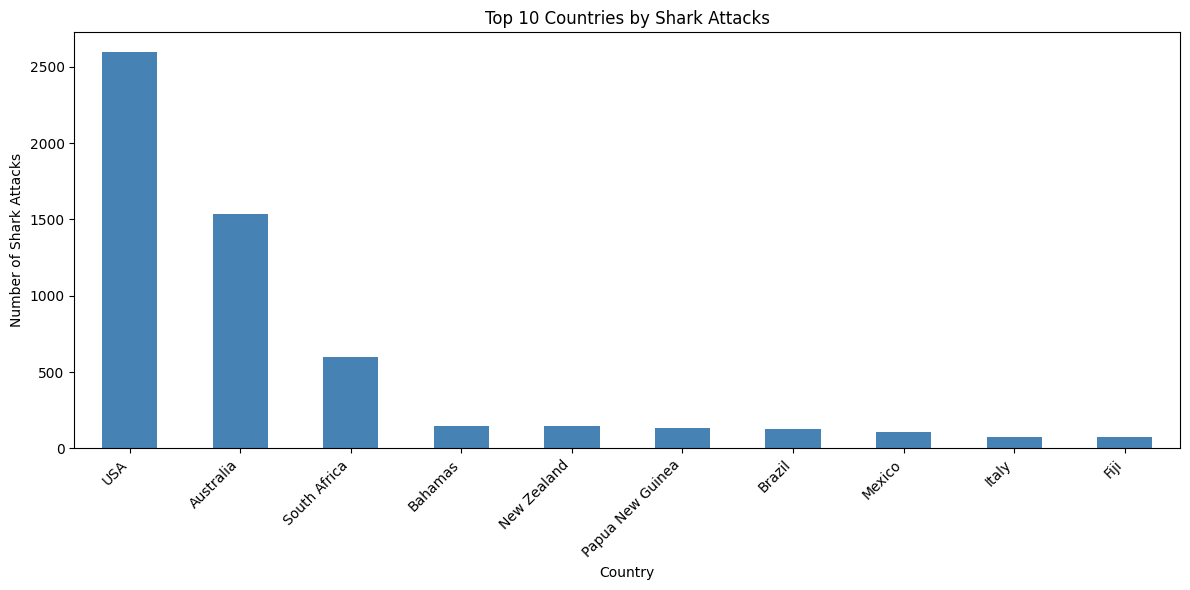

In [8]:
import matplotlib.pyplot as plt

# Select the top 10 countries
top_countries = df_clean[
    df_clean["Country"] != "Unknown"
]["Country"].value_counts().head(10)

# Create bar chart
plt.figure(figsize=(12, 6))

top_countries.plot(kind="bar", color="steelblue")

plt.title("Top 10 Countries by Shark Attacks")
plt.xlabel("Country")
plt.ylabel("Number of Shark Attacks")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

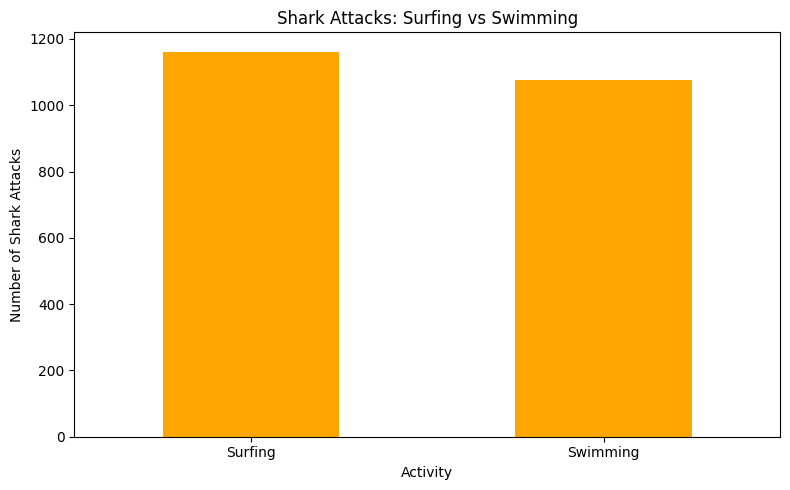

Activity
Surfing     1162
Swimming    1075
Name: count, dtype: int64


In [9]:
# Compare surfing and swimming attacks
activities = df_clean[
    df_clean["Activity"].isin(["Surfing", "Swimming"])
]

# Count attacks by activity
activity_counts = activities["Activity"].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

activity_counts.plot(kind="bar", color="orange")

plt.title("Shark Attacks: Surfing vs Swimming")
plt.xlabel("Activity")
plt.ylabel("Number of Shark Attacks")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Display exact numbers
print(activity_counts)

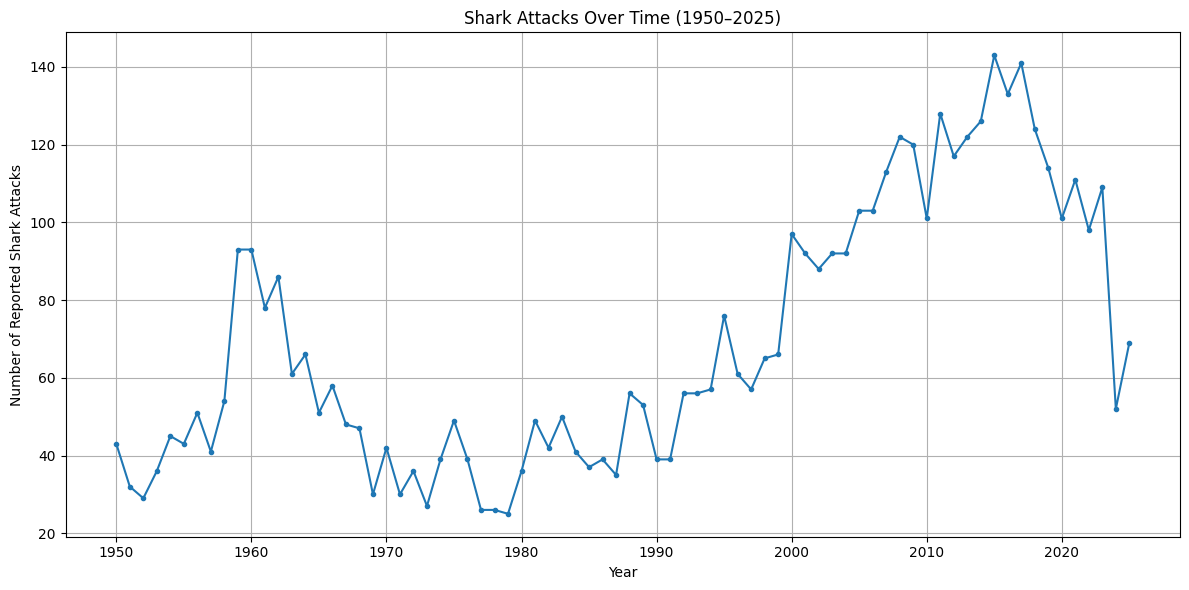

In [10]:
# Convert Year to numeric values
df_clean["Year"] = pd.to_numeric(
    df_clean["Year"], errors="coerce"
)

# Select years from 1950 to 2025
year_data = df_clean[
    (df_clean["Year"] >= 1950) &
    (df_clean["Year"] <= 2025)
]

# Count shark attacks per year
attacks_per_year = year_data["Year"].value_counts().sort_index()

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    attacks_per_year.index,
    attacks_per_year.values,
    marker="o",
    markersize=3
)

plt.title("Shark Attacks Over Time (1950–2025)")
plt.xlabel("Year")
plt.ylabel("Number of Reported Shark Attacks")

plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
# Final data quality check

print("Dataset shape:")
print(df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

print("\nFirst five rows:")
display(df_clean.head())

Dataset shape:
(7125, 22)

Missing values:
Date                 0
Year                 2
Type                18
Country              0
State              487
Location           567
Activity             0
Name               218
Sex                  0
Age               2994
Injury              36
Fatal Y/N          561
Time              3527
Species           3131
Source              20
pdf                326
href formula       331
href               329
Case Number        327
Case Number.1      328
original order     326
Age_Clean         3173
dtype: int64

Duplicate rows:
0

Data types:
Date               object
Year              float64
Type               object
Country            object
State              object
Location           object
Activity           object
Name               object
Sex                object
Age                object
Injury             object
Fatal Y/N          object
Time               object
Species            object
Source             object
pdf             

,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Time,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Age_Clean
0,18th September,2026.0,Unprovoked,Australia,Western Australia,Sorrento Beach Perth,Swimming,Greg O'Neil,M,63,...,1015hrs,Great White Shark 6m (20ft),Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,63.0
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of Perce Le Bilbo dive site,Diving,Unknown Male,M,?,...,1030hrs,Great White Shark,Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini Island,Swimming,Unknown Austrian Tourist,F,37,...,1730hrs,Unknown,Kevin McMurray Trackingsharks.com: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,37.0
3,13th September,2026.0,Unprovoked,Australia,Western Australia,Geraldton,Surfing,Mel Ismail,M,50's,...,0945hrs,Unknown,Simon De Marchi,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7th September,2026.0,Unprovoked,USA,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24,...,1640hrs,Tiger Shark suspected,Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,24.0


In [12]:
%%writefile cleaning.py

import pandas as pd

def clean_shark_data(df):
    # Create a copy
    data = df.copy()

    # Remove unnecessary columns
    data = data.drop(
        columns=["Unnamed: 21", "Unnamed: 22"],
        errors="ignore"
    )

    # Remove duplicate rows
    data = data.drop_duplicates()

    # Handle missing values
    for col in ["Country", "Activity", "Sex"]:
        data[col] = data[col].fillna("Unknown")

    # Clean country names
    data["Country"] = data["Country"].str.strip().str.title()

    data["Country"] = data["Country"].replace({
        "Usa": "USA",
        "United States": "USA",
        "U.S.A.": "USA"
    })

    # Clean activity names
    data["Activity"] = data["Activity"].str.strip().str.title()

    # Clean sex values
    data["Sex"] = data["Sex"].str.strip().str.upper()

    # Convert age to numeric
    data["Age_Clean"] = pd.to_numeric(
        data["Age"], errors="coerce"
    )

    # Convert year to numeric
    data["Year"] = pd.to_numeric(
        data["Year"], errors="coerce"
    )

    return data

Writing cleaning.py


In [13]:
# Import our cleaning function
from cleaning import clean_shark_data

# Apply the cleaning function
df_clean = clean_shark_data(df)

# Check the results
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print("\nFirst five rows:")
display(df_clean.head())

Original dataset: (7125, 23)
Cleaned dataset: (7125, 22)

First five rows:


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Time,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Age_Clean
0,18th September,2026.0,Unprovoked,Australia,Western Australia,Sorrento Beach Perth,Swimming,Greg O'Neil,M,63,...,1015hrs,Great White Shark 6m (20ft),Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,63.0
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of Perce Le Bilbo dive site,Diving,Unknown Male,M,?,...,1030hrs,Great White Shark,Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini Island,Swimming,Unknown Austrian Tourist,F,37,...,1730hrs,Unknown,Kevin McMurray Trackingsharks.com: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,37.0
3,13th September,2026.0,Unprovoked,Australia,Western Australia,Geraldton,Surfing,Mel Ismail,M,50's,...,0945hrs,Unknown,Simon De Marchi,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7th September,2026.0,Unprovoked,USA,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24,...,1640hrs,Tiger Shark suspected,Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,24.0


In [14]:
%%writefile README.md
# Shark Attack Data Analysis

## Project Overview
This project analyzes historical shark attack records using Python and Pandas.

The goal is to clean the dataset, explore patterns, and test three hypotheses.

## Dataset
- Original records: 7,125
- Original columns: 23
- Source file: GSAF5.xls

## Hypotheses
1. The USA and Australia have the highest number of reported shark attacks.
2. More shark attacks are reported during surfing than swimming.
3. The number of reported shark attacks changes over time.

## Data Cleaning
The following techniques were applied:
1. Removing unnecessary columns
2. Checking and removing duplicate rows
3. Handling missing values
4. Standardizing text values
5. Converting data types

## Exploratory Data Analysis
The analysis includes:
- Top 10 countries by reported shark attacks
- Surfing vs Swimming
- Shark attacks over time (1950-2025)

## Key Findings
- USA: 2,597 reported attacks
- Australia: 1,538 reported attacks
- Surfing: 1,162 reported attacks
- Swimming: 1,075 reported attacks
- Reported attacks fluctuate considerably over time.

These results describe reported incidents, not individual shark attack risk.

## Technologies
- Python
- Pandas
- Matplotlib
- Google Colab

## Project Files
- shark_attacks_analysis.ipynb
- cleaning.py
- README.md
- GSAF5.xls

## How to Run
1. Install pandas, matplotlib and xlrd.
2. Open the notebook.
3. Load GSAF5.xls.
4. Run the notebook cells in order.

Writing README.md
